=== 1. DESCARGA, EXTRACCIÓN Y CARGA DE DATOS ===
📥 Descargando dataset NSL-KDD...
✓ Archivos extraídos correctamente.
✓ Carga exitosa: 148517 registros × 43 columnas.

=== 2. AUDITORÍA DE INTEGRIDAD Y EXPLORACIÓN INICIAL ===

-------------------- MUESTRA DE DATOS (HEAD 5) --------------------
   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_same_srv_rate  \
0               0       0    0  ...                    0.17   
1               0       0    0  ...                    0.00   
2               0       0    0  ...                    0.10   
3               0    

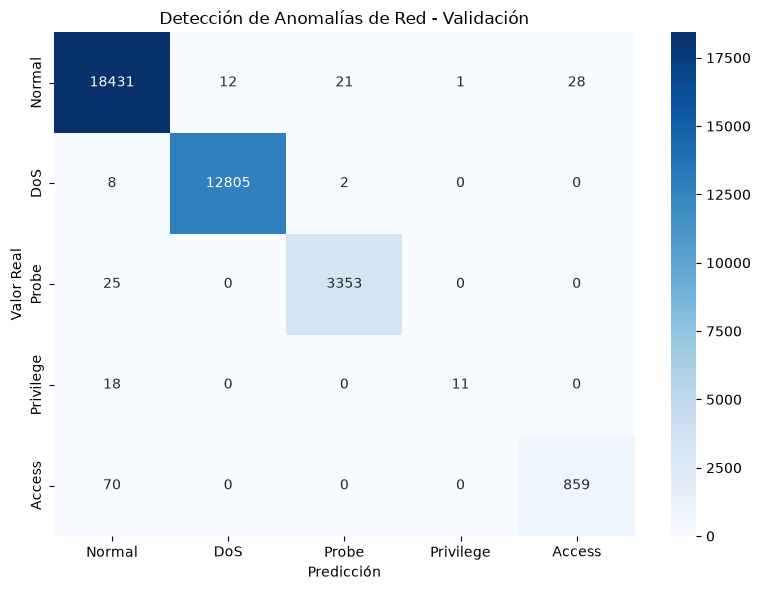


=== 8. EVALUACIÓN EN EL SUBCONJUNTO DE TEST FINAL ===
📊 MÉTRICAS DE TEST FINAL:
• Accuracy  : 0.9949 (99.49%)
• Precision : 0.9948 (99.48%)
• Recall    : 0.9949 (99.49%)
• F1-Score  : 0.9948 (99.48%)

-------------------- REPORTE DE CLASIFICACIÓN (TEST FINAL) --------------------
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00     15411
         DoS       1.00      1.00      1.00     10679
       Probe       0.99      0.99      0.99      2816
   Privilege       0.83      0.42      0.56        24
      Access       0.97      0.92      0.94       774

    accuracy                           0.99     29704
   macro avg       0.96      0.86      0.90     29704
weighted avg       0.99      0.99      0.99     29704



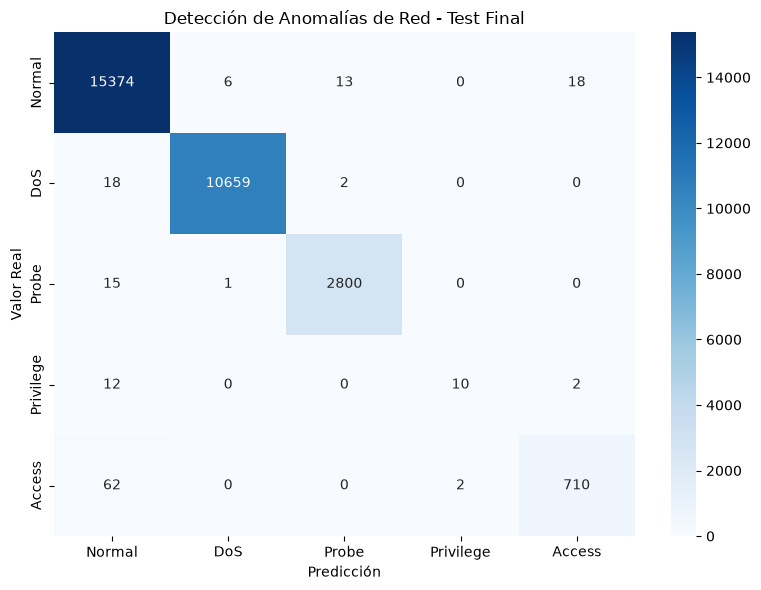


=== 9. PERSISTENCIA Y VERIFICACIÓN DEL MODELO ===
💾 Modelo serializado guardado exitosamente en: 'network_anomaly_detection_model.joblib'
• Tamaño en disco: 21.56 MB

🎉 Flujo completo de Network Anomaly Detection ejecutado y verificado correctamente.


In [5]:
import io
import os
import zipfile
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# ==============================================================================
# 1. DESCARGA, EXTRACCIÓN Y CARGA DEL DATASET NSL-KDD
# ==============================================================================
print("=" * 70)
print("=== 1. DESCARGA, EXTRACCIÓN Y CARGA DE DATOS ===")
print("=" * 70)

url = "https://cdn.services-k8s.prod.aws.htb.systems/content/modules/292/KDD_dataset.zip"
print("📥 Descargando dataset NSL-KDD...")
response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
  z.extractall(".")
print("✓ Archivos extraídos correctamente.")

columns = [
    "duration",
    "protocol_type",
    "service",
    "flag",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "attack",
    "level",
]

file_path = "KDD+.txt"
df = pd.read_csv(file_path, names=columns)

assert (
    df.shape[1] == 43
), f"Error: Se esperaban 43 columnas, pero se leyeron {df.shape[1]}"
print(f"✓ Carga exitosa: {df.shape[0]} registros × {df.shape[1]} columnas.")


# ==============================================================================
# 2. AUDITORÍA DE INTEGRIDAD Y EXPLORACIÓN INICIAL (EDA)
# ==============================================================================
print("\n" + "=" * 70)
print("=== 2. AUDITORÍA DE INTEGRIDAD Y EXPLORACIÓN INICIAL ===")
print("=" * 70)

print("\n-------------------- MUESTRA DE DATOS (HEAD 5) --------------------")
print(df.head())

print("\n-------------------- INFORMACIÓN ESTRUCTURAL --------------------")
df.info()

print("\n-------------------- ESTADÍSTICAS DESCRIPTIVAS --------------------")
print(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].head(10))

print(
    "\n-------------------- VERIFICACIÓN DE NULOS Y DUPLICADOS"
    " --------------------"
)
total_nulls = df.isnull().sum().sum()
total_duplicates = df.duplicated().sum()

print(f"• Total de valores nulos o faltantes : {total_nulls}")
print(f"• Registros exactamente duplicados  : {total_duplicates}")

assert total_nulls == 0, "Error: Se detectaron valores nulos en el dataset base."
print("✓ Calidad de datos confirmada: 0 valores nulos.")


# ==============================================================================
# 3. MAPEADO DE TARGETS Y VALIDACIÓN DE COHERENCIA
# ==============================================================================
print("\n" + "=" * 70)
print("=== 3. MAPEADO DE TARGETS Y VALIDACIÓN DE COHERENCIA ===")
print("=" * 70)

df["attack"] = df["attack"].astype(str).str.strip().str.lower()

# Target Binario (0: Normal, 1: Ataque)
df["attack_flag"] = df["attack"].apply(lambda a: 0 if a == "normal" else 1)

# Categorías tácticas de ataques
dos_attacks = {
    "apache2",
    "back",
    "land",
    "neptune",
    "mailbomb",
    "pod",
    "processtable",
    "smurf",
    "teardrop",
    "udpstorm",
    "worm",
}
probe_attacks = {"ipsweep", "mscan", "nmap", "portsweep", "saint", "satan"}
privilege_attacks = {
    "buffer_overflow",
    "loadmdoule",
    "loadmodule",
    "perl",
    "ps",
    "rootkit",
    "sqlattack",
    "xterm",
}
access_attacks = {
    "ftp_write",
    "guess_passwd",
    "httptunnel",
    "http_tunnel",
    "imap",
    "multihop",
    "named",
    "phf",
    "sendmail",
    "snmpgetattack",
    "snmpguess",
    "spy",
    "warezclient",
    "warezmaster",
    "xclock",
    "xsnoop",
}


def map_attack(attack_name):
  if attack_name == "normal":
    return 0  # Normal
  elif attack_name in dos_attacks:
    return 1  # DoS
  elif attack_name in probe_attacks:
    return 2  # Probe
  elif attack_name in privilege_attacks:
    return 3  # U2R (Privilege)
  elif attack_name in access_attacks:
    return 4  # R2L (Access)
  else:
    return 1  # Asignación segura por defecto (Ataque genérico si no está tabulado)


df["attack_map"] = df["attack"].apply(map_attack)

# Validación de Coherencia
coherence_check = (df["attack_flag"] == (df["attack_map"] > 0).astype(int)).all()
assert (
    coherence_check
), "Error: Incoherencia detectada entre etiqueta binaria y multiclase."
print(
    "✓ Validación de Coherencia: `attack_flag` y `attack_map` están 100%"
    " alineados."
)

print("\n-------------------- DISTRIBUCIÓN MULTICLASE --------------------")
class_labels_map = {0: "Normal", 1: "DoS", 2: "Probe", 3: "Privilege", 4: "Access"}
for k, v in df["attack_map"].value_counts().sort_index().items():
  print(
      f"Clase {k} ({class_labels_map[k]}): {v} registros"
      f" ({v/len(df)*100:.2f}%)"
  )


# ==============================================================================
# 4. CODIFICACIÓN CATEGÓRICA Y ENSAMBLADO DE CARACTERÍSTICAS
# ==============================================================================
print("\n" + "=" * 70)
print("=== 4. CODIFICACIÓN Y ENSAMBLADO DE CARACTERÍSTICAS ===")
print("=" * 70)

features_to_encode = ["protocol_type", "service"]
encoded = pd.get_dummies(df[features_to_encode], dtype=int)

numeric_features = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
]

train_set = encoded.join(df[numeric_features])
multi_y = df["attack_map"]

assert (
    train_set.isnull().sum().sum() == 0
), "Error: Se generaron nulos al unir matrices."
print(
    f"✓ Matriz ensamblada exitosamente: {train_set.shape[0]} filas ×"
    f" {train_set.shape[1]} columnas."
)


# ==============================================================================
# 5. DIVISIÓN Y AUDITORÍA DE SUBCONJUNTOS (TRAIN / VAL / TEST)
# ==============================================================================
print("\n" + "=" * 70)
print("=== 5. PARTISIONADO Y AUDITORÍA DE SUBCONJUNTOS ===")
print("=" * 70)

train_X, test_X, train_y, test_y = train_test_split(
    train_set, multi_y, test_size=0.2, random_state=1337, stratify=multi_y
)

multi_train_X, multi_val_X, multi_train_y, multi_val_y = train_test_split(
    train_X, train_y, test_size=0.3, random_state=1337, stratify=train_y
)

total_records = len(df)
assert (
    len(multi_train_X) + len(multi_val_X) + len(test_X) == total_records
), "Error: La suma de particiones no coincide con el total original."
assert (
    multi_train_X.shape[1] == multi_val_X.shape[1] == test_X.shape[1]
), "Error: Desalineación en el número de columnas entre subconjuntos."

print(
    f"• Subconjunto Entrenamiento : {multi_train_X.shape[0]} muestras"
    f" ({len(multi_train_X)/total_records*100:.2f}%)"
)
print(
    f"• Subconjunto Validación    : {multi_val_X.shape[0]} muestras"
    f" ({len(multi_val_X)/total_records*100:.2f}%)"
)
print(
    f"• Subconjunto Prueba        : {test_X.shape[0]} muestras"
    f" ({len(test_X)/total_records*100:.2f}%)"
)


# ==============================================================================
# 6. ENTRENAMIENTO DEL MODELO RANDOM FOREST
# ==============================================================================
print("\n" + "=" * 70)
print("=== 6. ENTRENAMIENTO DEL MODELO RANDOM FOREST ===")
print("=" * 70)

rf_model_multi = RandomForestClassifier(random_state=1337, n_jobs=-1)
print("🚀 Entrenando RandomForestClassifier multiclase...")
rf_model_multi.fit(multi_train_X, multi_train_y)
print("✓ Modelo ajustado correctamente.")


# ==============================================================================
# 7. EVALUACIÓN EN EL CONJUNTO DE VALIDACIÓN
# ==============================================================================
print("\n" + "=" * 70)
print("=== 7. EVALUACIÓN EN EL SUBCONJUNTO DE VALIDACIÓN ===")
print("=" * 70)

multi_predictions = rf_model_multi.predict(multi_val_X)
assert len(multi_predictions) == len(
    multi_val_y
), "Error: Cantidad de predicciones difiere del vector objetivo de validación."

val_accuracy = accuracy_score(multi_val_y, multi_predictions)
val_precision = precision_score(
    multi_val_y, multi_predictions, average="weighted", zero_division=0
)
val_recall = recall_score(
    multi_val_y, multi_predictions, average="weighted", zero_division=0
)
val_f1 = f1_score(
    multi_val_y, multi_predictions, average="weighted", zero_division=0
)

print("📊 MÉTRICAS DE VALIDACIÓN:")
print(f"• Accuracy  : {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"• Precision : {val_precision:.4f} ({val_precision*100:.2f}%)")
print(f"• Recall    : {val_recall:.4f} ({val_recall*100:.2f}%)")
print(f"• F1-Score  : {val_f1:.4f} ({val_f1*100:.2f}%)")

target_class_names = ["Normal", "DoS", "Probe", "Privilege", "Access"]

print(
    "\n-------------------- REPORTE DE CLASIFICACIÓN (VALIDACIÓN)"
    " --------------------"
)
print(
    classification_report(
        multi_val_y,
        multi_predictions,
        target_names=target_class_names,
        zero_division=0,
    )
)

# Matriz de Confusión - Validación
conf_matrix_val = confusion_matrix(multi_val_y, multi_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_class_names,
    yticklabels=target_class_names,
)
plt.title("Detección de Anomalías de Red - Validación")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()


# ==============================================================================
# 8. EVALUACIÓN EN EL CONJUNTO DE TEST FINAL
# ==============================================================================
print("\n" + "=" * 70)
print("=== 8. EVALUACIÓN EN EL SUBCONJUNTO DE TEST FINAL ===")
print("=" * 70)

test_multi_predictions = rf_model_multi.predict(test_X)
assert len(test_multi_predictions) == len(
    test_y
), "Error: Cantidad de predicciones difiere del vector objetivo de test."

test_accuracy = accuracy_score(test_y, test_multi_predictions)
test_precision = precision_score(
    test_y, test_multi_predictions, average="weighted", zero_division=0
)
test_recall = recall_score(
    test_y, test_multi_predictions, average="weighted", zero_division=0
)
test_f1 = f1_score(
    test_y, test_multi_predictions, average="weighted", zero_division=0
)

print("📊 MÉTRICAS DE TEST FINAL:")
print(f"• Accuracy  : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"• Precision : {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"• Recall    : {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"• F1-Score  : {test_f1:.4f} ({test_f1*100:.2f}%)")

print(
    "\n-------------------- REPORTE DE CLASIFICACIÓN (TEST FINAL)"
    " --------------------"
)
print(
    classification_report(
        test_y,
        test_multi_predictions,
        target_names=target_class_names,
        zero_division=0,
    )
)

# Matriz de Confusión - Test
conf_matrix_test = confusion_matrix(test_y, test_multi_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_class_names,
    yticklabels=target_class_names,
)
plt.title("Detección de Anomalías de Red - Test Final")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()


# ==============================================================================
# 9. PERSISTENCIA DEL MODELO Y COMPROBACIÓN EN DISCO
# ==============================================================================
print("\n" + "=" * 70)
print("=== 9. PERSISTENCIA Y VERIFICACIÓN DEL MODELO ===")
print("=" * 70)

model_filename = "network_anomaly_detection_model.joblib"
joblib.dump(rf_model_multi, model_filename)

assert os.path.exists(
    model_filename
), f"Error: No se pudo verificar la creación de '{model_filename}' en disco."
file_size_mb = os.path.getsize(model_filename) / (1024 * 1024)

print(f"💾 Modelo serializado guardado exitosamente en: '{model_filename}'")
print(f"• Tamaño en disco: {file_size_mb:.2f} MB")
print(
    "\n🎉 Flujo completo de Network Anomaly Detection ejecutado y verificado"
    " correctamente."
)